# Steps 6 + 7: Entity-faithful decoding, NLI verification and the final evaluation

**Step 6**
1. **Entity re-ranking:** LED generates 6 beam candidates per judgment. Each is scored by *recall of the key entities* (the ones in the control prefix) minus the *share of entities that do not appear in the source judgment*; the best candidate is kept. (The control prefix itself was trained in Step 5.)
2. **NLI verification:** every summary sentence is checked against its 3 most similar source sentences (InLegalBERT cosine) with a DeBERTa-v3 NLI model. A sentence with P(entailment) below the threshold is replaced by its best-matching source sentence (or dropped).

**Step 7:** one results table over all systems (Lead, TextRank, Oracle, MLP-only, GNN, GNN+diffusion+MMR, plain LED if you ran Step 5b, LED, LED + re-ranking, full pipeline) with ROUGE-1/2/L, BERTScore (chunked, no 512-token truncation), entity hallucination, entity recall, NLI-supported sentences, paired-bootstrap significance, a manual-review sheet of flagged sentences, and a blinded expert-rating packet.

**Runtime: T4 GPU.** Candidate generation is the slow part (saved per document; resumable). Edit the paths in cell 2.

In [1]:
!pip -q install -U transformers rouge-score rapidfuzz bert-score sentencepiece protobuf scikit-learn tqdm pandas
from google.colab import drive
drive.mount('/content/drive')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
Mounted at /content/drive


In [2]:
# ============ EDIT THESE (same BASE as Steps 0-5) ============
BASE      = "/content/drive/MyDrive/inabs_project"
GRAPH_DIR = f"{BASE}/graphs"          # Step 1
GNN_DIR   = f"{BASE}/gnn"             # Step 2
EXT_DIR   = f"{BASE}/extractive"      # Steps 3+4
LED_DIR   = f"{BASE}/led"             # Step 5
PLAIN_DIR = f"{BASE}/led_plain"       # Step 5b (optional plain-LED baseline); ignored if missing
OUT_DIR   = f"{BASE}/final"           # this notebook
# =============================================================

# ---- must match Step 5
MAX_INPUT_TOKENS, USE_ENTITY_PREFIX, PREFIX_ENTITIES = 4096, True, 8
NO_REPEAT_NGRAM, LENGTH_PENALTY, MIN_WORDS_OK = 3, 2.0, 50
# ---- Step 6a: entity re-ranking
N_CAND  = 6          # beam candidates per document (4-8)
GEN_BATCH = 1        # documents per generate() call
HALL_W, RANK_W = 1.0, 0.05    # score = key-entity recall - HALL_W * hallucinated-entity share + RANK_W * (beam-rank bonus)
FUZZY_THR = 90       # near-exact matching of entities against the source (rapidfuzz partial_ratio)
# ---- Step 6b: NLI verification
NLI_MODEL       = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"
RETRIEVER_MODEL = "law-ai/InLegalBERT"      # falls back to TF-IDF if it cannot be loaded
TOP_PREMISE     = 3
NLI_THRESHOLD, NLI_ACTION = 0.5, "replace"  # "replace" the sentence by its best source sentence, or "drop" it
AUTO_TUNE_NLI   = False                     # True = pick (threshold, action) with the best validation ROUGE from the sweep
NLI_GRID_TAUS   = [0.3, 0.5, 0.7]
# ---- Step 7
BERTSCORE_MODEL, BERTSCORE_LAYER = "roberta-large", 17     # = the bert-score default for English
COMPUTE_ROUGE_L = True       # official ROUGE-L (~0.5 s per summary)
N_BOOT = 10000
EXPERT_DOCS = 10             # documents in the expert-rating packet (x 2 systems = 20 summaries)
SEED = 42
ALLOW_CPU = False

In [3]:
import os, re, json, math, time, gc, random, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
import transformers
from transformers import AutoTokenizer, AutoModel, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification

HAS_GPU = torch.cuda.is_available()
if not HAS_GPU and not ALLOW_CPU:
    raise RuntimeError("No GPU found. In Colab: Runtime > Change runtime type > T4 GPU, then rerun.")
DEVICE = torch.device("cuda" if HAS_GPU else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"transformers {transformers.__version__} | torch {torch.__version__} | device {torch.cuda.get_device_name(0) if HAS_GPU else 'CPU'}")
for d in ("candidates", "summaries", "figures", "expert"): Path(OUT_DIR, d).mkdir(parents=True, exist_ok=True)

EVAL_SPLITS = ["validate", "test"]
GR = {}
for split in EVAL_SPLITS:
    for p in sorted(Path(GRAPH_DIR, split).glob("*.pt")):
        g = torch.load(p, map_location="cpu", weights_only=True); GR[(split, g["doc_id"])] = g
SEL = json.load(open(Path(EXT_DIR, "selections_final.json")))["docs"]
GEN5 = json.load(open(Path(LED_DIR, "generations.json")))            # Step 5 output: defines which documents are evaluated
DOCSET = {s: sorted(GEN5[s]) for s in EVAL_SPLITS if s in GEN5}
print({s: len(v) for s, v in DOCSET.items()}, "documents (validate = the small sanity subset, test = all)")
assert "test" in DOCSET, "led/generations.json has no test documents - run Step 5 first"
LED_STATS = json.load(open(Path(LED_DIR, "token_stats.json")))
GEN_MAX, GEN_MIN = int(LED_STATS["gen_max_length"]), int(LED_STATS["gen_min_length"])
pre = torch.load(Path(GNN_DIR, "preproc.pt"), weights_only=True); BUDGET = int(pre["budget"])
SRC_TEXT = {k: " ".join(g["sentences"]) for k, g in GR.items()}

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


transformers 5.24.0 | torch 2.14.1+cu130 | device Tesla T4
{'validate': 10, 'test': 100} documents (validate = the small sanity subset, test = all)


## 1. Text utilities: sentence splitting, rule-based legal entity extraction, and the entity-support test
The same extractor is applied to every system, to the reference and to the source, so all comparisons are like-for-like. Support is checked against the **full source judgment** (exact, then near-exact match).

In [4]:
try:
    from rapidfuzz import fuzz as rf_fuzz
    HAS_RF = True
except ImportError:
    HAS_RF = False; print("rapidfuzz missing: only exact entity matching")

def norm_text(t):
    t = str(t).lower().replace("&", " and ")
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]|_", " ", t)).strip()

# ---------- sentence splitting (protects legal abbreviations and initials)
ABBR = ["Mr", "Mrs", "Ms", "Dr", "Sri", "Shri", "Smt", "No", "Nos", "Co", "Ltd", "Pvt", "Sec", "Secs", "Art", "Arts", "Vs", "Ors", "Anr",
        "Messrs", "St", "Hon", "Re", "Cr", "Cl", "Ch", "Para", "Paras", "Vol", "Ex", "Rs", "Addl", "Dy", "Govt", "Corp", "Inc", "Jr", "Sr",
        "Prof", "Esq", "Cf", "viz", "i.e", "e.g", "etc"]
_ABBR_RE = re.compile(r"\b(" + "|".join(re.escape(a) for a in ABBR) + r")\.", re.I)
_INIT_RE = re.compile(r"\b([A-Z])\.")
def split_sentences(text):
    t = " ".join(str(text).split())
    t = _ABBR_RE.sub(lambda m: m.group(1) + "<DOT>", t)
    t = _INIT_RE.sub(lambda m: m.group(1) + "<DOT>", t)
    parts = re.split(r"(?<=[.!?])\s+(?=[\"'(\[]?[A-Z0-9])", t)
    return [p.replace("<DOT>", ".").strip() for p in parts if p.strip()]

# ---------- rule-based legal entity extraction
STOP = set("""the a an this that these those it its he she they we i you in on at by for of to and but or if as with from under upon over after
before held appeal appeals appellant appellants respondent respondents petitioner petitioners plaintiff plaintiffs defendant defendants court courts
judgment judgement order orders act acts section sections article articles rule rules case cases however thus therefore hence accordingly also
further moreover whereas where when while whether there then so such no not any all both each other another one two three first second third
state states government central union january february march april may june july august september october november december bench learned counsel
mr mrs shri sri smt dr hon justice chief petition writ suit decree""".split())
CONNECT = {"of", "and", "&", "the", "for"}
JUDGE_SUFFIX = {"J", "JJ", "CJ"}
KEEP_IN_NAMES = {"court", "courts", "act", "acts", "state", "states", "union", "central", "government", "bench", "commission", "tribunal", "board"}
LEAD_TRIM = STOP - KEEP_IN_NAMES          # words trimmed from the START of a capitalised run (sentence openers, honorifics)
PROV_RE = re.compile(r"\b(Sections?|Secs?\.?|Articles?|Arts?\.?|Orders?|Rules?|Clauses?|Paragraphs?)\s+(\d+[A-Za-z]?(?:\([A-Za-z0-9]+\))*"
                     r"(?:\s*(?:,|and|&|to)\s*\d+[A-Za-z]?(?:\([A-Za-z0-9]+\))*)*)")
YEAR_RE = re.compile(r"\b(1[5-9]\d\d|20\d\d)\b")
_KW = {"section": "section", "sections": "section", "sec": "section", "secs": "section", "article": "article", "articles": "article",
       "art": "article", "arts": "article", "order": "order", "orders": "order", "rule": "rule", "rules": "rule",
       "clause": "clause", "clauses": "clause", "paragraph": "paragraph", "paragraphs": "paragraph"}
_CAP = re.compile(r"^[A-Z][A-Za-z\.\-']*$")
def _clean(w): return w.strip(".,;:()[]{}\"'\u201c\u201d\u2018\u2019!?")

def extract_entities(text):
    """normalised entity strings: provisions ('section 34'), years, and runs of capitalised words (courts, acts, judges, parties)"""
    text = str(text); out = []
    for m in PROV_RE.finditer(text):
        kw = _KW.get(m.group(1).lower().rstrip("."), m.group(1).lower())
        out += [f"{kw} {n.lower()}" for n in re.findall(r"\d+[A-Za-z]?", re.sub(r"\([A-Za-z0-9]+\)", "", m.group(2)))]
    out += YEAR_RE.findall(text)
    toks = text.split(); n = len(toks)
    clean = [_clean(t) for t in toks]; cap = [bool(_CAP.match(c)) for c in clean]
    def sentence_start(i):
        if i == 0: return True
        p = toks[i - 1]
        return p.endswith((".", "!", "?", ":")) and not (len(clean[i - 1]) <= 1 or clean[i - 1].rstrip(".") in ABBR or clean[i - 1] in JUDGE_SUFFIX)
    mid = Counter(clean[i].lower() for i in range(n) if cap[i] and not sentence_start(i))
    i = 0
    while i < n:
        if not cap[i]: i += 1; continue
        run, k = [clean[i]], i + 1
        ended = toks[i].endswith((",", ";", ":")) or (toks[i].endswith((".", "!", "?")) and clean[i] not in JUDGE_SUFFIX and len(clean[i]) > 1 and clean[i] not in ABBR)
        if clean[i] in JUDGE_SUFFIX: ended = True
        while not ended and k < n:
            if cap[k]: run.append(clean[k])
            elif clean[k].lower() in CONNECT and k + 1 < n and cap[k + 1] and not toks[k - 1].endswith((",", ";")): run.append(clean[k])
            else: break
            ended = toks[k].endswith((",", ";", ":")) or clean[k] in JUDGE_SUFFIX or (toks[k].endswith((".", "!", "?")) and len(clean[k]) > 1 and clean[k] not in ABBR)
            k += 1
        start = i; i = k
        while run and (run[0].lower() in LEAD_TRIM or run[0].lower() in CONNECT): run.pop(0); start += 1
        while run and (run[-1].lower() in CONNECT or run[-1] in JUDGE_SUFFIX): run.pop()
        if not run: continue
        if len(run) == 1:
            w = run[0]
            if len(w) < 3 or w.lower() in STOP: continue
            if sentence_start(start) and mid[w.lower()] == 0: continue
        e = norm_text(" ".join(run))
        if e: out.append(e)
    seen, res = set(), []
    for e in out:
        if e and e not in seen: seen.add(e); res.append(e)
    return res

# ---------- support test
def make_src(text):
    n = norm_text(text)
    return dict(norm=n, ents=set(extract_entities(text)), toks=set(n.split()))
def contains(hay_norm, ent): return f" {ent} " in f" {hay_norm} "
def supported(ent, src):
    if ent in src["ents"] or contains(src["norm"], ent): return True
    if HAS_RF and len(ent) >= 8 and not any(c.isdigit() for c in ent):
        return rf_fuzz.partial_ratio(ent, src["norm"]) >= FUZZY_THR
    return False
def novel_token(ent, src): return any((len(t) >= 3 or t.isdigit()) and t not in src["toks"] for t in ent.split())

SRC = {k: make_src(t) for k, t in SRC_TEXT.items()}

# ---------- unit checks
s = ("Held, the Calcutta High Court under Section 34 of the Arbitration Act, 1940 set aside the award of Fazal Ali J. in "
     "Mair & Co. v. Gordhandass Sagarmull. The Bengal Chamber of Commerce referred to Sections 10 and 11.")
e = extract_entities(s)
for want in ["calcutta high court", "section 34", "arbitration act", "1940", "fazal ali", "bengal chamber of commerce", "section 10", "section 11"]:
    assert want in e, (want, e)
assert "held" not in e and "the" not in e
assert any("gordhandass sagarmull" in x for x in e) and any(x.startswith("mair") for x in e), e
assert split_sentences("Mr. A. M. Mair appeared. The appeal was dismissed. It is so ordered.") == ["Mr. A. M. Mair appeared.", "The appeal was dismissed.", "It is so ordered."]
_t = make_src("Sections 34 and 35 of the Act apply to the High Court of Calcutta.")
assert supported("section 35", _t) and supported("calcutta", _t) and not supported("section 36", _t)
_src = make_src("The Calcutta High Court set aside the award under Section 34 of the Arbitration Act. Fazal Ali J. delivered the judgment in 1950.")
_hal = extract_entities("Justice Ramaswamy held under Section 99 of the Arbitration Act in 1950 at the Calcutta High Court.")
assert sorted(x for x in _hal if not supported(x, _src)) == ["ramaswamy", "section 99"], [x for x in _hal if not supported(x, _src)]
assert novel_token("ramaswamy", _src) and not novel_token("fazal ali", _src)
print("text-utility checks passed. Example entities:", e[:8])

text-utility checks passed. Example entities: ['section 34', 'section 10', 'section 11', '1940', 'calcutta high court', 'arbitration act', 'fazal ali', 'mair and co']


## 2. Step 6a: generate beam candidates with the fine-tuned LED (saved per document, resumable)

In [5]:
def prefix_entities(g, idx):
    cnt = Counter(e for j in idx for e in g["sent_entities"][j])
    return [e for e, _ in sorted(cnt.items(), key=lambda kv: (-kv[1], kv[0]))[:PREFIX_ENTITIES]]
def make_source(g, idx):
    ents = prefix_entities(g, idx) if USE_ENTITY_PREFIX else []
    head = ("entities: " + " ; ".join(ents) + " || ") if ents else ""
    return head + " ".join(g["sentences"][j] for j in idx), ents

# the prefix must be rebuilt exactly as in Step 5
for s in DOCSET:
    for d in DOCSET[s]:
        assert make_source(GR[(s, d)], SEL[s][d]["led_input_idx"])[1] == GEN5[s][d]["prefix_entities"], \
            "entity-prefix settings differ from Step 5 (check USE_ENTITY_PREFIX / PREFIX_ENTITIES)"

CAND = {}                                                         # (split, doc) -> list of candidate summaries
todo = []
for s in DOCSET:
    Path(OUT_DIR, "candidates", s).mkdir(parents=True, exist_ok=True)
    for d in DOCSET[s]:
        f = Path(OUT_DIR, "candidates", s, d + ".json")
        if f.exists(): CAND[(s, d)] = json.load(open(f))
        else: todo.append((s, d, f))
print(f"{len(CAND)} documents already have candidates, {len(todo)} to generate")

if todo:
    tok = AutoTokenizer.from_pretrained(str(Path(LED_DIR, "final_model")))
    led = AutoModelForSeq2SeqLM.from_pretrained(str(Path(LED_DIR, "final_model")))
    led = (led.half() if HAS_GPU else led).to(DEVICE).eval()

    @torch.no_grad()
    def gen_candidates(sources, beams):
        enc = tok(sources, max_length=MAX_INPUT_TOKENS, truncation=True, padding=True, return_tensors="pt").to(DEVICE)
        gam = torch.zeros_like(enc["input_ids"]); gam[:, 0] = 1
        out = led.generate(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], global_attention_mask=gam,
                           num_beams=beams, num_return_sequences=beams, no_repeat_ngram_size=NO_REPEAT_NGRAM,
                           length_penalty=LENGTH_PENALTY, max_length=GEN_MAX, min_length=min(GEN_MIN, GEN_MAX - 1), early_stopping=True)
        txt = [t.strip() for t in tok.batch_decode(out, skip_special_tokens=True)]
        return [txt[i * beams:(i + 1) * beams] for i in range(len(sources))]

    todo.sort(key=lambda j: len(SRC_TEXT[(j[0], j[1])]))
    t0 = time.time()
    for i in tqdm(range(0, len(todo), GEN_BATCH), desc="candidates"):
        batch = todo[i:i + GEN_BATCH]; sources = [make_source(GR[(s, d)], SEL[s][d]["led_input_idx"])[0] for s, d, _ in batch]
        try:
            res = gen_candidates(sources, N_CAND)
        except torch.cuda.OutOfMemoryError if HAS_GPU else RuntimeError:
            gc.collect(); torch.cuda.empty_cache() if HAS_GPU else None
            print("  out of memory: retrying one document at a time with fewer beams")
            res = [gen_candidates([src], max(2, N_CAND // 2))[0] for src in sources]
        for (s, d, f), cands in zip(batch, res):
            cands = [c for c in cands if len(c.split()) >= MIN_WORDS_OK] or [SEL[s][d]["extractive_text"]]     # never leave a document empty
            json.dump(cands, open(f, "w")); CAND[(s, d)] = cands
    print(f"candidate generation: {(time.time() - t0) / 60:.1f} min")
    del led; gc.collect()
    if HAS_GPU: torch.cuda.empty_cache()

0 documents already have candidates, 110 to generate


Loading weights:   0%|          | 0/296 [00:00<?, ?it/s]

candidates:   0%|          | 0/110 [00:00<?, ?it/s]

[transformers] Input ids are automatically padded from 560 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 559 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 649 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 929 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1193 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1176 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1343 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1277 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically p

candidate generation: 20.3 min


## 3. Step 6a: entity re-ranking
score = (share of the key entities from the control prefix that the candidate mentions) − HALL_W × (share of the candidate's entities that do not occur in the source) + a small bonus for a better beam rank. Candidates under 50 words are penalised.

In [6]:
def cand_stats(text, key_ents, src):
    ents = extract_entities(text); tn = norm_text(text)
    hall = float(np.mean([not supported(e, src) for e in ents])) if ents else 0.0
    rec = float(np.mean([contains(tn, k) for k in key_ents])) if key_ents else 0.0
    return rec, hall

def rerank(split, d):
    cands, key, src = CAND[(split, d)], GEN5[split][d]["prefix_entities"], SRC[(split, d)]
    best, info = None, []
    for r, c in enumerate(cands):
        rec, hall = cand_stats(c, key, src)
        sc = rec - HALL_W * hall + RANK_W * (len(cands) - 1 - r) / max(len(cands) - 1, 1) - (1.0 if len(c.split()) < MIN_WORDS_OK else 0.0)
        info.append((sc, rec, hall))
        if best is None or sc > info[best][0]: best = r
    return best, info

PICK, rows = {}, []
for s in DOCSET:
    for d in DOCSET[s]:
        b, info = rerank(s, d); PICK[(s, d)] = b
        rows.append(dict(split=s, changed=b != 0, rec0=info[0][1], recB=info[b][1], hall0=info[0][2], hallB=info[b][2], n=len(CAND[(s, d)])))
R = pd.DataFrame(rows)
for s, g in R.groupby("split"):
    print(f"[{s}] re-ranking changed the choice in {int(g.changed.sum())}/{len(g)} documents | key-entity recall {g.rec0.mean():.2%} -> {g.recB.mean():.2%} | "
          f"hallucinated-entity share {g.hall0.mean():.2%} -> {g.hallB.mean():.2%} | candidates per document {g.n.mean():.1f}")

[test] re-ranking changed the choice in 14/100 documents | key-entity recall 59.01% -> 60.30% | hallucinated-entity share 9.90% -> 9.46% | candidates per document 6.0
[validate] re-ranking changed the choice in 1/10 documents | key-entity recall 62.74% -> 62.74% | hallucinated-entity share 9.43% -> 8.91% | candidates per document 6.0


## 4. Step 6b: NLI verification (DeBERTa-v3 NLI cross-encoder + InLegalBERT retrieval of the premise)

In [7]:
# ---- NLI model
nli_tok = AutoTokenizer.from_pretrained(NLI_MODEL)
nli = AutoModelForSequenceClassification.from_pretrained(NLI_MODEL)
nli = (nli.half() if HAS_GPU else nli).to(DEVICE).eval()
ENT_IDX = [int(i) for i, l in nli.config.id2label.items() if "entail" in str(l).lower()][0]
print("NLI model:", NLI_MODEL, "| labels:", dict(nli.config.id2label), "| entailment index:", ENT_IDX)

# ---- retriever (InLegalBERT mean-pooled embeddings; TF-IDF fallback)
RETRIEVER = "inlegalbert"
try:
    r_tok = AutoTokenizer.from_pretrained(RETRIEVER_MODEL); r_model = AutoModel.from_pretrained(RETRIEVER_MODEL)
    r_model = (r_model.half() if HAS_GPU else r_model).to(DEVICE).eval()
except Exception as ex:
    RETRIEVER = "tfidf"; print(f"could not load {RETRIEVER_MODEL} ({type(ex).__name__}); using TF-IDF retrieval instead")
print("retriever:", RETRIEVER)

@torch.no_grad()
def embed(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        enc = r_tok([" ".join(t.split()[:150]) for t in texts[i:i + bs]], truncation=True, max_length=256, padding=True, return_tensors="pt").to(DEVICE)
        h = r_model(**{k: v for k, v in enc.items() if k in ("input_ids", "attention_mask", "token_type_ids")}).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
        out.append(F.normalize(((h * m).sum(1) / m.sum(1).clamp(min=1)).float(), dim=-1).cpu())
    return torch.cat(out)

_SRC_EMB = {}
def sim_matrix(key, hyps):
    """[len(hyps), n_source_sentences] cosine similarity"""
    src = GR[key]["sentences"]
    if RETRIEVER == "inlegalbert":
        if key not in _SRC_EMB: _SRC_EMB[key] = embed(src)
        return (embed(hyps) @ _SRC_EMB[key].T).numpy()
    from sklearn.feature_extraction.text import TfidfVectorizer
    v = TfidfVectorizer(sublinear_tf=True).fit(src + hyps)
    return (v.transform(hyps) @ v.transform(src).T).toarray()

@torch.no_grad()
def nli_probs(premises, hyps, bs=16):
    out = []
    for i in range(0, len(hyps), bs):
        enc = nli_tok(premises[i:i + bs], hyps[i:i + bs], truncation="only_first", max_length=512, padding=True, return_tensors="pt").to(DEVICE)
        out += torch.softmax(nli(**enc).logits.float(), -1)[:, ENT_IDX].cpu().tolist()
    return out

def nli_check(key, summary):
    """per summary sentence: P(entailment | its top-3 most similar source sentences)"""
    hyps = split_sentences(summary) or [summary]; src = GR[key]["sentences"]
    top = np.argsort(-sim_matrix(key, hyps), axis=1)[:, :TOP_PREMISE]
    prem = [" ".join(" ".join(src[j].split()[:120]) for j in sorted(row)) for row in top]
    p = nli_probs(prem, [" ".join(h.split()[:150]) for h in hyps])
    return [dict(sent=h, p=float(pp), top=[int(x) for x in row], best=int(row[0]), premise=pr) for h, pp, row, pr in zip(hyps, p, top, prem)]

def repair(info, src_sents, tau, action):
    out, used, changed = [], set(), 0
    for it in info:
        if it["p"] >= tau: out.append(it["sent"]); continue
        changed += 1
        if action == "replace" and it["best"] not in used: out.append(src_sents[it["best"]]); used.add(it["best"])
    if not out: return " ".join(i["sent"] for i in info), 0
    return " ".join(out), changed

def supported_share(info, tau=0.5): return float(np.mean([i["p"] >= tau for i in info])) if info else float("nan")

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.28k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

... (10 outputs left out)

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: law-ai/InLegalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


retriever: inlegalbert


In [8]:
from rouge_score import rouge_scorer
SC12 = rouge_scorer.RougeScorer(["rouge1", "rouge2"], use_stemmer=True)

# ---- validation sweep (threshold x action). NLI is run once per summary; the repairs are free.
NLI_INFO = {}
for s in DOCSET:
    for d in tqdm(DOCSET[s], desc=f"NLI {s}"):
        NLI_INFO[(s, d)] = nli_check((s, d), CAND[(s, d)][PICK[(s, d)]])

val_docs = [("validate", d) for d in DOCSET.get("validate", [])]
if val_docs:
    sweep = []
    for tau in [0.0] + NLI_GRID_TAUS:                                   # tau = 0 means "no NLI repair"
        for action in (["replace", "drop"] if tau > 0 else ["none"]):
            r12, hall, chg, w = [], [], [], []
            for key in val_docs:
                txt, c = repair(NLI_INFO[key], GR[key]["sentences"], tau, action) if tau > 0 else (CAND[key][PICK[key]], 0)
                sc = SC12.score(GR[key]["reference"], txt); r12.append((sc["rouge1"].fmeasure + sc["rouge2"].fmeasure) / 2)
                ents = extract_entities(txt); hall.append(np.mean([not supported(e, SRC[key]) for e in ents]) if ents else 0.0)
                chg.append(c / max(len(NLI_INFO[key]), 1)); w.append(len(txt.split()))
            sweep.append(dict(threshold=tau, action=action, rouge12_x100=round(np.mean(r12) * 100, 2), entity_hallucination_pct=round(np.mean(hall) * 100, 2),
                              sentences_changed_pct=round(np.mean(chg) * 100, 1), words=round(np.mean(w))))
    SWEEP = pd.DataFrame(sweep); SWEEP.to_csv(Path(OUT_DIR, "nli_sweep_validation.csv"), index=False)
    print(f"NLI threshold sweep on {len(val_docs)} validation documents (small sample, treat as a guide):"); print(SWEEP.to_string(index=False))
    if AUTO_TUNE_NLI:
        best = SWEEP[SWEEP.threshold > 0].sort_values("rouge12_x100", ascending=False).iloc[0]
        NLI_THRESHOLD, NLI_ACTION = float(best.threshold), str(best.action)
print(f"\nNLI setting used: threshold {NLI_THRESHOLD}, action '{NLI_ACTION}'")

NLI validate:   0%|          | 0/10 [00:00<?, ?it/s]

NLI test:   0%|          | 0/100 [00:00<?, ?it/s]

NLI threshold sweep on 10 validation documents (small sample, treat as a guide):
 threshold  action  rouge12_x100  entity_hallucination_pct  sentences_changed_pct  words
       0.0    none         44.39                      8.91                    0.0    618
       0.3 replace         40.39                      4.05                   45.5    973
       0.3    drop         38.16                      8.09                   45.5    314
       0.5 replace         40.58                      3.44                   51.2    966
       0.5    drop         35.90                      9.65                   51.2    265
       0.7 replace         40.83                      2.91                   56.3    957
       0.7    drop         34.57                      9.66                   56.3    230

NLI setting used: threshold 0.5, action 'replace'


## 5. Build the three LED-based systems for every document and save them

In [9]:
LED_SYS = {"top": {}, "rerank": {}, "full": {}}              # (split, doc) -> text
n_changed = []
for key in NLI_INFO:
    s, d = key
    LED_SYS["top"][key] = CAND[key][0]
    LED_SYS["rerank"][key] = CAND[key][PICK[key]]
    LED_SYS["full"][key], c = repair(NLI_INFO[key], GR[key]["sentences"], NLI_THRESHOLD, NLI_ACTION)
    n_changed.append((s, c, len(NLI_INFO[key])))
    for name in LED_SYS:
        p = Path(OUT_DIR, "summaries", name, s); p.mkdir(parents=True, exist_ok=True); (p / f"{d}.txt").write_text(LED_SYS[name][key], encoding="utf-8")
for s in DOCSET:
    ch = [c / n for sp, c, n in n_changed if sp == s]
    print(f"[{s}] NLI changed {np.mean(ch):.1%} of the summary sentences on average")

[validate] NLI changed 51.2% of the summary sentences on average
[test] NLI changed 56.0% of the summary sentences on average


## 6. Step 7: all systems on the test documents

In [10]:
TEST = [("test", d) for d in DOCSET["test"]]
def select_topk(scores, words, budget):
    chosen, w = [], 0
    for i in np.argsort(-np.asarray(scores), kind="stable"):
        chosen.append(int(i)); w += words[i]
        if w >= budget: break
    return sorted(chosen)

def joined(g, idx): return " ".join(g["sentences"][j] for j in idx)
def textrank_idx(g):
    E = g["x"][:, :g["emb_dim"]].numpy().astype(np.float32); E = E - E.mean(0, keepdims=True)
    E = E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-8); S = np.clip(E @ E.T, 0, None); np.fill_diagonal(S, 0)
    rs = S.sum(1, keepdims=True); rs[rs == 0] = 1; P = S / rs; n = len(S); r = np.full(n, 1.0 / n, dtype=np.float32)
    for _ in range(50): r = 0.15 / n + 0.85 * (P.T @ r)
    return select_topk(r, g["sent_words"].tolist(), BUDGET)

def stored_scores(name, seed):
    d = torch.load(Path(GNN_DIR, "preds", f"{name}_seed{seed}.pt"), weights_only=True)
    return {(s, doc): t.numpy() for s in d for doc, t in d[s].items()}
def best_seed(name):
    runs = [json.load(open(p)) for p in Path(GNN_DIR, "runs").glob(f"{name}_seed*.json")]
    return max(runs, key=lambda r: r["val"]["score"])["seed"] if runs else None

SYSTEMS = {}
SYSTEMS["Lead (first sentences)"]            = {k: joined(GR[k], select_topk(np.arange(GR[k]["num_nodes"])[::-1], GR[k]["sent_words"].tolist(), BUDGET)) for k in TEST}
SYSTEMS["TextRank (InLegalBERT similarity)"] = {k: joined(GR[k], textrank_idx(GR[k])) for k in TEST}
SYSTEMS["Oracle (upper bound)"]              = {k: joined(GR[k], sorted(GR[k]["oracle_idx"])) for k in TEST}
sd = best_seed("mlp_feat")
if sd is not None:
    S_ = stored_scores("mlp_feat", sd); SYSTEMS["MLP-only extractive"] = {k: joined(GR[k], select_topk(S_[k], GR[k]["sent_words"].tolist(), BUDGET)) for k in TEST}
bp = Path(GNN_DIR, "best_run.json"); sd = json.load(open(bp))["seed"] if bp.exists() else best_seed("gnn_full")
if sd is not None:
    S_ = stored_scores("gnn_full", sd); SYSTEMS["GNN, no diffusion (top-k)"] = {k: joined(GR[k], select_topk(S_[k], GR[k]["sent_words"].tolist(), BUDGET)) for k in TEST}
SYSTEMS["GNN + diffusion + MMR (extractive)"] = {k: SEL["test"][k[1]]["extractive_text"] for k in TEST}
pg = Path(PLAIN_DIR, "generations.json")
if pg.exists():
    PL = json.load(open(pg)).get("test", {})
    if all(k[1] in PL for k in TEST): SYSTEMS["Plain LED (truncated judgment)"] = {k: PL[k[1]]["summary"] for k in TEST}
    else: print("Step 5b output is incomplete for the test set -> plain-LED row skipped")
else:
    print("no led_plain/generations.json -> plain-LED baseline row skipped (run the optional Step 5b notebook to add it)")
SYSTEMS["LED (fine-tuned, top beam)"]           = {k: LED_SYS["top"][k] for k in TEST}
SYSTEMS["LED + entity re-ranking"]              = {k: LED_SYS["rerank"][k] for k in TEST}
SYSTEMS["Full pipeline (LED + entity control + re-ranking + NLI)"] = {k: LED_SYS["full"][k] for k in TEST}
print(len(SYSTEMS), "systems:", list(SYSTEMS))

no led_plain/generations.json -> plain-LED baseline row skipped (run the optional Step 5b notebook to add it)
9 systems: ['Lead (first sentences)', 'TextRank (InLegalBERT similarity)', 'Oracle (upper bound)', 'MLP-only extractive', 'GNN, no diffusion (top-k)', 'GNN + diffusion + MMR (extractive)', 'LED (fine-tuned, top beam)', 'LED + entity re-ranking', 'Full pipeline (LED + entity control + re-ranking + NLI)']


## 7. BERTScore without the 512-token cut
The `bert-score` package silently truncates at 512 tokens, which would compare only the first third of a long summary. Here the text is encoded in 510-token chunks with the same model and layer (roberta-large, layer 17), and the greedy token matching is done over the *whole* document. The package's rescaling baseline is applied when available.

In [11]:
bs_tok = AutoTokenizer.from_pretrained(BERTSCORE_MODEL)
bs_model = AutoModel.from_pretrained(BERTSCORE_MODEL, output_hidden_states=True)
bs_model = (bs_model.half() if HAS_GPU else bs_model).to(DEVICE).eval()
CH = min(510, int(getattr(bs_model.config, "max_position_embeddings", 512)) - 2)
CLS = bs_tok.cls_token_id if bs_tok.cls_token_id is not None else bs_tok.bos_token_id
SEP = bs_tok.sep_token_id if bs_tok.sep_token_id is not None else bs_tok.eos_token_id

@torch.no_grad()
def bs_embed(text):
    ids = bs_tok(str(text), add_special_tokens=False, truncation=False)["input_ids"]
    out = []
    for i in range(0, len(ids), CH):
        x = torch.tensor([[CLS] + ids[i:i + CH] + [SEP]], device=DEVICE)
        h = bs_model(input_ids=x, attention_mask=torch.ones_like(x)).hidden_states[BERTSCORE_LAYER][0, 1:-1]
        out.append(F.normalize(h.float(), dim=-1).cpu())
    return torch.cat(out) if out else torch.zeros(0, bs_model.config.hidden_size)

BASELINE = None
try:
    import bert_score
    bp_ = Path(bert_score.__file__).parent / "rescale_baseline" / "en" / f"{BERTSCORE_MODEL}.tsv"
    bdf = pd.read_csv(bp_); bdf = pd.read_csv(bp_, sep="\t") if "LAYER" not in bdf.columns else bdf
    row = bdf[bdf.LAYER == BERTSCORE_LAYER].iloc[0]; BASELINE = float(row.F)
except Exception: pass
print("BERTScore rescaling baseline:", "none found (raw scores)" if BASELINE is None else f"{BASELINE:.4f} (rescaled F1)")

_REF_EMB = {}
def bertscore_f1(cand, key):
    if key not in _REF_EMB: _REF_EMB[key] = bs_embed(GR[key]["reference"])
    C, Rr = bs_embed(cand), _REF_EMB[key]
    if len(C) == 0 or len(Rr) == 0: return float("nan")
    sim = C @ Rr.T; P, Rc = sim.max(1).values.mean().item(), sim.max(0).values.mean().item()
    f = 2 * P * Rc / (P + Rc + 1e-12)
    return (f - BASELINE) / (1 - BASELINE) if BASELINE is not None else f

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERTScore rescaling baseline: 0.8312 (rescaled F1)


## 8. Evaluate every system on every test document, then the results table

In [12]:
SC = rouge_scorer.RougeScorer(["rouge1", "rouge2"] + (["rougeL"] if COMPUTE_ROUGE_L else []), use_stemmer=True)
REF_ENTS = {k: extract_entities(GR[k]["reference"]) for k in TEST}

def nli_share(key, text):
    if text == LED_SYS["rerank"].get(key) and key in NLI_INFO: return supported_share(NLI_INFO[key])       # already computed
    return supported_share(nli_check(key, text))

rows = []
for name, texts in SYSTEMS.items():
    for key in tqdm(TEST, desc=name[:40], leave=False):
        t, g, src = texts[key], GR[key], SRC[key]
        sc = SC.score(g["reference"], t); ents = extract_entities(t); tsrc = make_src(t)
        rows.append(dict(system=name, doc_id=key[1], r1=sc["rouge1"].fmeasure, r2=sc["rouge2"].fmeasure, rl=sc["rougeL"].fmeasure if COMPUTE_ROUGE_L else np.nan,
                         bertscore=bertscore_f1(t, key),
                         hall=np.mean([not supported(e, src) for e in ents]) if ents else np.nan,
                         novel=np.mean([novel_token(e, src) for e in ents]) if ents else np.nan,
                         ent_recall=np.mean([supported(e, tsrc) for e in REF_ENTS[key]]) if REF_ENTS[key] else np.nan,
                         nli_sup=nli_share(key, t), words=len(t.split())))
PER_DOC = pd.DataFrame(rows); PER_DOC.to_csv(Path(OUT_DIR, "per_document_metrics.csv"), index=False)

BS_COL = "BERTScore F1 (rescaled)" if BASELINE is not None else "BERTScore F1 (raw)"
def agg(g):
    r = {"R-1": g.r1.mean() * 100, "R-2": g.r2.mean() * 100}
    if COMPUTE_ROUGE_L: r["R-L"] = g.rl.mean() * 100
    r.update({BS_COL: g.bertscore.mean() * 100, "Entity halluc. % (lower=better)": g.hall.mean() * 100,
              "Novel-token entities %": g.novel.mean() * 100, "Entity recall vs ref %": g.ent_recall.mean() * 100,
              "NLI-supported sent. %": g.nli_sup.mean() * 100, "Words": g.words.mean()})
    return pd.Series(r)
TABLE = PER_DOC.groupby("system", sort=False).apply(agg).round(2).reset_index()
TABLE.to_csv(Path(OUT_DIR, "results_table.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(TABLE.to_string(index=False))

hr = np.nanmean([np.mean([not supported(e, SRC[k]) for e in REF_ENTS[k]]) if REF_ENTS[k] else np.nan for k in TEST]) * 100
print(f"\nCalibration: the HUMAN reference summaries have an entity-hallucination rate of {hr:.1f}% under this extractor "
      f"(they paraphrase, and the extractor is rule-based), so rates near that level are the realistic floor for abstractive output.")
print("Extractive systems copy sentences, so their entity hallucination is ~0 by construction. NLI-supported % is measured with threshold 0.5; "
      "the full pipeline is optimised against this same NLI model, so rely on the entity metrics and the human ratings as the independent evidence.")

Lead (first sentences):   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1102 > 512). Running this sequence through the model will result in indexing errors


TextRank (InLegalBERT similarity):   0%|          | 0/100 [00:00<?, ?it/s]

Oracle (upper bound):   0%|          | 0/100 [00:00<?, ?it/s]

MLP-only extractive:   0%|          | 0/100 [00:00<?, ?it/s]

GNN, no diffusion (top-k):   0%|          | 0/100 [00:00<?, ?it/s]

GNN + diffusion + MMR (extractive):   0%|          | 0/100 [00:00<?, ?it/s]

LED (fine-tuned, top beam):   0%|          | 0/100 [00:00<?, ?it/s]

LED + entity re-ranking:   0%|          | 0/100 [00:00<?, ?it/s]

Full pipeline (LED + entity control + re:   0%|          | 0/100 [00:00<?, ?it/s]

                                                 system   R-1   R-2   R-L  BERTScore F1 (rescaled)  Entity halluc. % (lower=better)  Novel-token entities %  Entity recall vs ref %  NLI-supported sent. %   Words
                                 Lead (first sentences) 52.63 30.64 29.12                    16.00                             0.00                    0.00                   53.68                  64.55 1024.42
                      TextRank (InLegalBERT similarity) 54.84 33.84 30.75                    20.65                             0.00                    0.00                   47.36                  52.97 1119.03
                                   Oracle (upper bound) 71.03 53.30 46.59                    36.78                             0.31                    0.00                   60.75                  56.92 1130.46
                                    MLP-only extractive 55.94 35.75 32.27                    22.83                             0.30                    0.00 

## 9. Significance: paired bootstrap over test documents (full pipeline vs the other systems)

In [13]:
FULL = "Full pipeline (LED + entity control + re-ranking + NLI)"
wide = {m: PER_DOC.pivot(index="doc_id", columns="system", values=m) for m in ("r1", "r2", "bertscore", "hall", "nli_sup")}
wide["rouge12"] = (wide["r1"] + wide["r2"]) / 2
rng = np.random.default_rng(0)
rivals = [n for n in ("GNN + diffusion + MMR (extractive)", "Plain LED (truncated judgment)", "LED (fine-tuned, top beam)", "LED + entity re-ranking") if n in SYSTEMS]
rows = []
for rival in rivals:
    for m, label, better in (("rouge12", "ROUGE (R1+R2)/2 x100", "higher"), ("bertscore", "BERTScore F1 x100", "higher"),
                             ("hall", "Entity hallucination x100", "lower"), ("nli_sup", "NLI-supported sentences x100", "higher")):
        d = (wide[m][FULL] - wide[m][rival]).dropna().values
        if len(d) < 2: continue
        bs = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(N_BOOT)])
        p = float((bs <= 0).mean()) if better == "higher" else float((bs >= 0).mean())
        rows.append({"Full pipeline vs": rival, "Metric": label, "mean difference": round(d.mean() * 100, 2),
                     "95% CI": f"[{np.percentile(bs, 2.5) * 100:.2f}, {np.percentile(bs, 97.5) * 100:.2f}]",
                     f"P(no improvement; {better}=better)": round(p, 3), "docs": len(d)})
BOOT = pd.DataFrame(rows); BOOT.to_csv(Path(OUT_DIR, "bootstrap.csv"), index=False)
print(BOOT.to_string(index=False))
print("\nA 95% CI that excludes 0 (and a small P) means the difference is unlikely to be noise on these", len(TEST), "test documents.")

                  Full pipeline vs                       Metric  mean difference         95% CI  P(no improvement; higher=better)  docs  P(no improvement; lower=better)
GNN + diffusion + MMR (extractive)         ROUGE (R1+R2)/2 x100            -2.98 [-4.42, -1.57]                             1.000   100                              NaN
GNN + diffusion + MMR (extractive)            BERTScore F1 x100            -1.04  [-2.59, 0.44]                             0.913   100                              NaN
GNN + diffusion + MMR (extractive)    Entity hallucination x100             3.68   [2.88, 4.50]                               NaN   100                              1.0
GNN + diffusion + MMR (extractive) NLI-supported sentences x100            11.27  [8.76, 13.76]                             0.000   100                              NaN
        LED (fine-tuned, top beam)         ROUGE (R1+R2)/2 x100            -1.37  [-2.98, 0.34]                             0.948   100                    

## 10. Spot-check sheet for the NLI-flagged sentences (the NLI model is general-domain, so review these by hand) and a summary figure

1202 sentences flagged on the test set; 40 written to nli_flagged_for_review.csv. Count how many a human agrees are unsupported; report that precision in your limitations section.


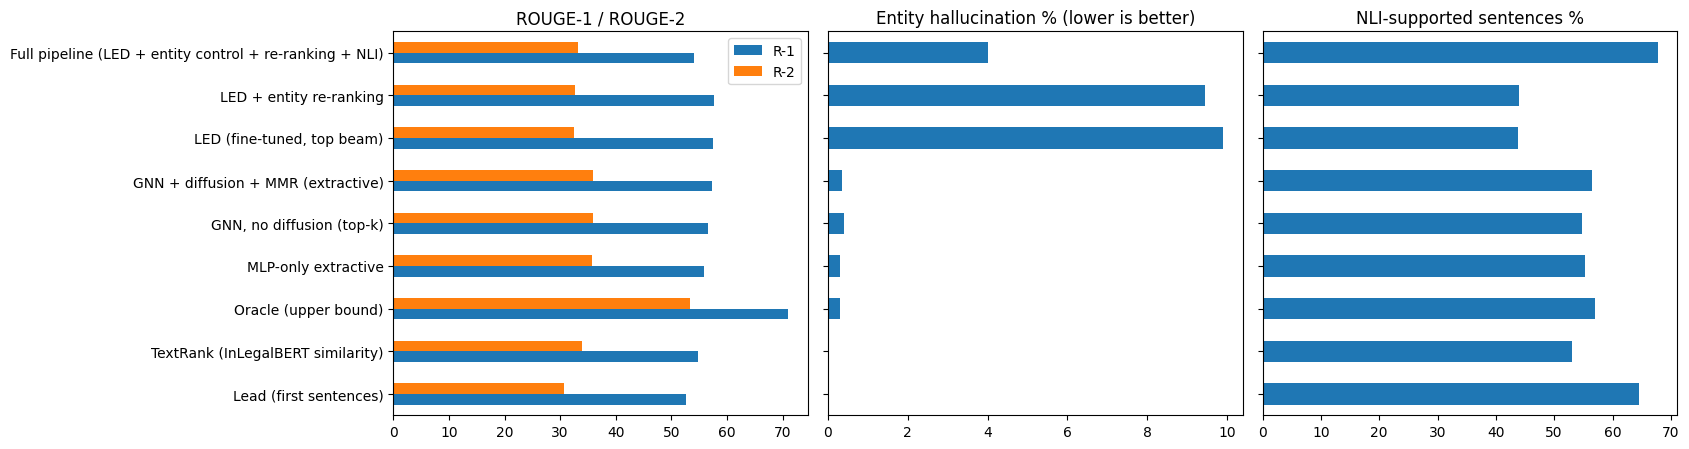

In [14]:
flag = []
for key, info in NLI_INFO.items():
    if key[0] != "test": continue
    for it in info:
        if it["p"] < NLI_THRESHOLD:
            flag.append(dict(doc_id=key[1], p_entailment=round(it["p"], 3), summary_sentence=it["sent"], retrieved_premise=it["premise"],
                             replaced_by=GR[key]["sentences"][it["best"]] if NLI_ACTION == "replace" else "(dropped)", manual_verdict_correctly_flagged_yes_no=""))
FL = pd.DataFrame(flag)
if len(FL): FL = FL.sample(min(40, len(FL)), random_state=SEED)
FL.to_csv(Path(OUT_DIR, "nli_flagged_for_review.csv"), index=False)
print(f"{len(flag)} sentences flagged on the test set; {len(FL)} written to nli_flagged_for_review.csv. "
      f"Count how many a human agrees are unsupported; report that precision in your limitations section.")

import matplotlib.pyplot as plt
T = TABLE.set_index("system")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a_, col, title in zip(ax, [("R-1", "R-2"), ("Entity halluc. % (lower=better)",), ("NLI-supported sent. %",)], ["ROUGE-1 / ROUGE-2", "Entity hallucination % (lower is better)", "NLI-supported sentences %"]):
    T[list(col)].plot.barh(ax=a_, legend=len(col) > 1); a_.set_title(title); a_.set_ylabel("")
    if a_ is not ax[0]: a_.set_yticklabels([])
plt.tight_layout(); plt.savefig(Path(OUT_DIR, "figures", "system_comparison.png"), dpi=130); plt.show()

## 11. Expert evaluation (your Review 1 suggestion)
Creates a **blinded** packet: 2 summaries per document (the full pipeline and the extractive system), shuffled, with the source judgment as a text file. Give each rater `expert/rating_sheet.csv` (or paste it into a Google Form / Sheet) to fill in coverage, faithfulness and readability on a 1-5 scale. When raters send their filled copies back, save them as `expert/ratings_<name>.csv` and run the analysis cell.

In [15]:
rng = random.Random(SEED); pick = rng.sample(sorted(DOCSET["test"]), min(EXPERT_DOCS, len(DOCSET["test"])))
pair = {"A_full_pipeline": SYSTEMS[FULL], "B_extractive": SYSTEMS["GNN + diffusion + MMR (extractive)"]}
items = [(d, name) for d in pick for name in pair]; rng.shuffle(items)
Path(OUT_DIR, "expert", "sources").mkdir(exist_ok=True)
sheet, key = [], []
for i, (d, name) in enumerate(items, 1):
    sheet.append(dict(item_id=f"S{i:02d}", source_file=f"sources/{d}.txt", summary=pair[name][("test", d)], coverage_1to5="", faithfulness_1to5="", readability_1to5="", comments=""))
    key.append(dict(item_id=f"S{i:02d}", doc_id=d, system=name))
    Path(OUT_DIR, "expert", "sources", f"{d}.txt").write_text(SRC_TEXT[("test", d)], encoding="utf-8")
pd.DataFrame(sheet).to_csv(Path(OUT_DIR, "expert", "rating_sheet.csv"), index=False)
pd.DataFrame(key).to_csv(Path(OUT_DIR, "expert", "KEY_do_not_share.csv"), index=False)
print(f"packet written to {Path(OUT_DIR, 'expert')}: {len(sheet)} summaries over {len(pick)} documents (system labels are hidden; the key is in KEY_do_not_share.csv)")
print("Rubric to give raters: coverage = does the summary include the key facts, issues and holding; faithfulness = is every statement supported by the judgment; "
      "readability = is it clear, coherent and well-formed. 1 = very poor, 5 = excellent.")

packet written to /content/drive/MyDrive/inabs_project/final/expert: 20 summaries over 10 documents (system labels are hidden; the key is in KEY_do_not_share.csv)
Rubric to give raters: coverage = does the summary include the key facts, issues and holding; faithfulness = is every statement supported by the judgment; readability = is it clear, coherent and well-formed. 1 = very poor, 5 = excellent.


In [16]:
from itertools import combinations
from sklearn.metrics import cohen_kappa_score
from scipy.stats import spearmanr
rf = sorted(Path(OUT_DIR, "expert").glob("ratings_*.csv"))
if not rf:
    print("no filled rating sheets found yet (expected files: expert/ratings_<rater>.csv). Run this cell again after collecting them.")
else:
    K = pd.read_csv(Path(OUT_DIR, "expert", "KEY_do_not_share.csv")); crit = ["coverage_1to5", "faithfulness_1to5", "readability_1to5"]
    R = {f.stem.replace("ratings_", ""): pd.read_csv(f).set_index("item_id")[crit].astype(float) for f in rf}
    allr = pd.concat([r.assign(rater=n).reset_index() for n, r in R.items()]).merge(K, on="item_id")
    print(f"{len(R)} raters, {allr.item_id.nunique()} items\n")
    print(allr.groupby("system")[crit].agg(["mean", "std"]).round(2).to_string())
    if len(R) >= 2:
        print("\nInter-rater agreement (mean over rater pairs):")
        for c in crit:
            ks, rs = [], []
            for a, b in combinations(R, 2):
                x, y = R[a][c].dropna(), R[b][c].dropna(); ix = x.index.intersection(y.index)
                ks.append(cohen_kappa_score(x[ix].astype(int), y[ix].astype(int), weights="quadratic")); rs.append(spearmanr(x[ix], y[ix])[0])
            print(f"  {c:20s} quadratic-weighted kappa {np.nanmean(ks):.2f} | Spearman rho {np.nanmean(rs):.2f}")

no filled rating sheets found yet (expected files: expert/ratings_<rater>.csv). Run this cell again after collecting them.


## 12. Final checks

In [17]:
files = {n: len(list(Path(OUT_DIR, "summaries", n, "test").glob("*.txt"))) for n in LED_SYS}
print("summary files per LED-based system (test):", files, "| expected", len(DOCSET["test"]))
assert all(v == len(DOCSET["test"]) for v in files.values())
assert PER_DOC.groupby("system").doc_id.nunique().min() == len(TEST)
print("outputs in", OUT_DIR, ":", sorted(p.name for p in Path(OUT_DIR).iterdir()))

summary files per LED-based system (test): {'top': 100, 'rerank': 100, 'full': 100} | expected 100
outputs in /content/drive/MyDrive/inabs_project/final : ['bootstrap.csv', 'candidates', 'expert', 'figures', 'nli_flagged_for_review.csv', 'nli_sweep_validation.csv', 'per_document_metrics.csv', 'results_table.csv', 'summaries']
